# Ultrasound - Phased Array

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch11/ch11-01.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** run the setup cell below first. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

In [ ]:
# --- Setup: run this cell first.  It does nothing outside Google Colab. ---
import sys, os, importlib.util, urllib.request
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # interactive matplotlib (%matplotlib widget) needs ipympl and Colab's custom widget manager
    if importlib.util.find_spec("ipympl") is None:
        get_ipython().run_line_magic("pip", "install -q ipympl")
        print("ipympl installed. Colab will restart the runtime once; when it has, run this cell again.")
        get_ipython().kernel.do_shutdown(restart=True)
    from google.colab import output
    output.enable_custom_widget_manager()

## Import libraries

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle

## Define parameters

In [3]:
# --- Parameters ---
vs = 10
d = 1
theta = np.deg2rad(45)  # Convert 45 degrees to radians

# --- Helper Functions ---
def r01(t):
    return vs * t

def ri1(index, t):
    # Calculate radius based on index and time
    val = r01(t) - index * d * np.sin(theta)
    # Replicate the If[ri1 >= 0, ri1, 0] logic
    return max(val, 0.0)



## Plot

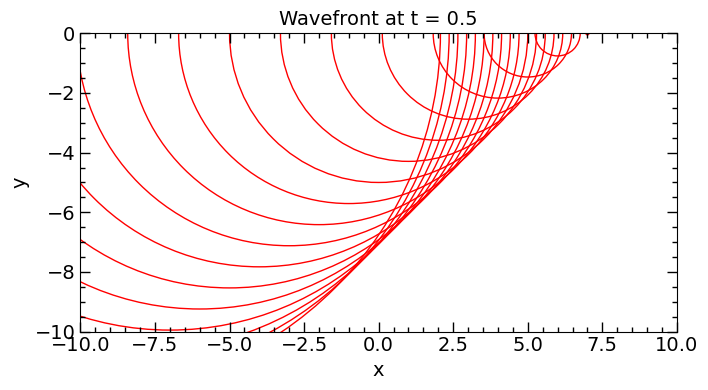

In [6]:
# --- Figure and Axes Setup ---
fig1, axes1 = plt.subplots(figsize=(8, 4))

# --- Plot Logic ---
indices = np.arange(-10, 11) # i from -10 to 10 inclusive

for i in indices:
    rad = ri1(i, t_val)
    if rad > 0:
        circle = Circle((i * d, 0), rad, fill=False, edgecolor='red')
        axes1.add_patch(circle)

# --- Styling and Formatting ---
# 1. Axis Labels and Title with increased font size
axes1.set_xlabel('x', fontsize=14)
axes1.set_ylabel('y', fontsize=14)
axes1.set_title(f"Wavefront at t = {t_val}", fontsize=14)

# 2. Tick Parameters (Previous requests + new font size)
axes1.minorticks_on()

# Apply direction and width to both major and minor ticks
axes1.tick_params(which='both', direction="in", width=1)

# Apply specific lengths to major vs minor
axes1.tick_params(which='major', length=7)
axes1.tick_params(which='minor', length=3.5)

# Apply font size to tick labels (usually applies to major ticks)
axes1.tick_params(axis='both', labelsize=14)

# Set ticks on all sides
axes1.xaxis.set_ticks_position('both')
axes1.yaxis.set_ticks_position('both')

# --- Limits and Aspect Ratio ---
axes1.set_xlim(-10, 10)
axes1.set_ylim(-10, 0)
axes1.set_aspect('equal')

plt.tight_layout() # Ensures labels don't get cut off
plt.show()

## Make interactive with ipywidgets

In [ ]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import ipywidgets as widgets
from IPython.display import display

# --- Parameters ---
vs = 10
d = 1
theta = np.deg2rad(45)

# --- Helper Functions ---
def r01(t):
    return vs * t

def ri1(index, t):
    val = r01(t) - index * d * np.sin(theta)
    return max(val, 0.0)

# --- 1. Setup the Figure and Axes ---
plt.ioff()
fig2, axes2 = plt.subplots(figsize=(8, 4))
fig2.canvas.header_visible = False 
plt.ion()

# --- 2. Apply Plot Parameters ---
axes2.set_xlabel('x', fontsize=14)
axes2.set_ylabel('y', fontsize=14)

# Set initial title
init_t = 0.0
axes2.set_title(f"Wavefront at t = {init_t:.2f}", fontsize=14)

axes2.minorticks_on()
axes2.tick_params(which='both', direction="in", width=1, labelsize=14)
axes2.tick_params(which='major', length=7)
axes2.tick_params(which='minor', length=3.5)
axes2.xaxis.set_ticks_position('both')
axes2.yaxis.set_ticks_position('both')

axes2.set_xlim(-10, 10)
axes2.set_ylim(-10, 0)
axes2.set_aspect('equal')
plt.tight_layout()

# --- 3. Initialize Graphics Objects ---
indices = np.arange(-10, 11)
circles = []

for i in indices:
    # FIX: Calculate the actual radius for init_t instead of using 0
    rad = ri1(i, init_t)
    circle = Circle((i * d, 0), rad, fill=False, edgecolor='red')
    axes2.add_patch(circle)
    circles.append(circle)

# --- 4. Define Fast Update Logic ---
def update_plot(change):
    t = change['new']
    axes2.set_title(f"Wavefront at t = {t:.2f}", fontsize=14)
    for i, circle in zip(indices, circles):
        rad = ri1(i, t)
        circle.set_radius(rad)
    fig2.canvas.draw_idle()

# --- 5. Create and Link Slider ---
slider = widgets.FloatSlider(
    value=init_t, min=-0.5, max=1.0, step=0.01, 
    description='Time (t):', continuous_update=True
)
slider.observe(update_plot, names='value')

display(slider)
display(fig2.canvas)

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch11/ch11-01_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch11/ch11-01.html) (direct link: [ch11-01_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch11/ch11-01_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.